# ARTI403 - Image Processing
## Lab 6: Frequency Domain



### Step 0: Install packages (run once)

In [1]:
%pip install -q numpy matplotlib scikit-image

Note: you may need to restart the kernel to use updated packages.


## Task#1: Filtering in the Frequency Domain (Laplacian)

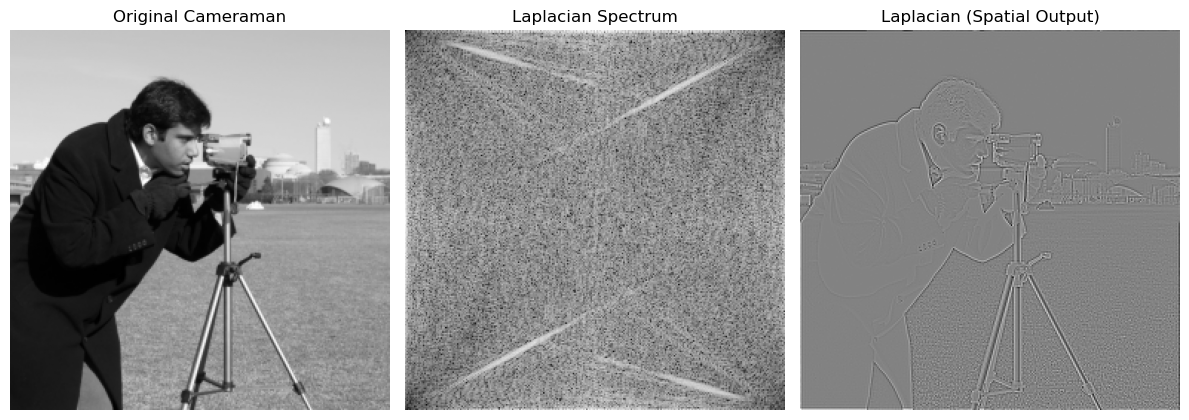

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize

# Load cameraman image (already grayscale)
image = data.camera()
image = resize(image, (256, 256))  # Resize for faster FFT (optional)

# Get image size
M, N = image.shape

# Generate frequency grid (centered)
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

# Compute Laplacian filter in frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# Apply 2D FFT
F = np.fft.fft2(image)

# Apply Laplacian filter in frequency domain
F_lap = F * laplacian_filter

# Inverse FFT to get spatial result
laplacian_image = np.fft.ifft2(F_lap).real

# Plot results
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(F_lap)), cmap='gray')
plt.title('Laplacian Spectrum')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap='gray')
plt.title('Laplacian (Spatial Output)')
plt.axis('off')

plt.tight_layout()
plt.show()

## Assessment

### Task#1: Apply the Sobel filter(s) in the frequency domain to the Cameraman image and show the results

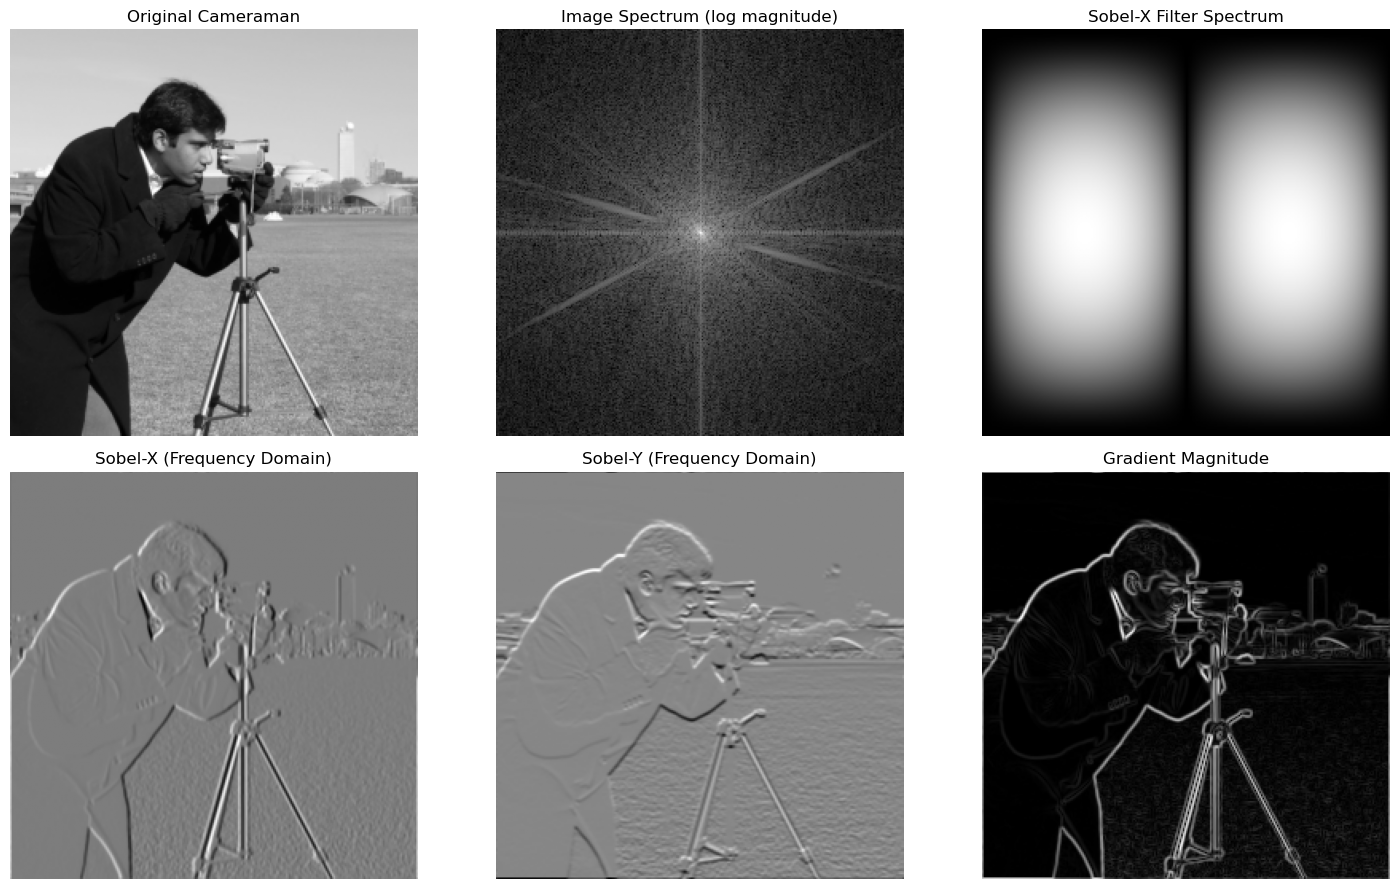

In [3]:
from numpy.fft import fft2, ifft2, fftshift, ifftshift

# Load and resize image
image = data.camera()
image = resize(image, (256, 256))

# Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    # Find center coordinates
    cy, cx = ph // 2, pw // 2
    # Insert kernel centered at the image center
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))  # Shift before FFT to place (0,0) at top-left

# Compute FFT of image
F_image = fft2(image)

# FFT of centered Sobel filters (use the provided function)
Hx = center_embed_kernel(sobel_x, image.shape)
Hy = center_embed_kernel(sobel_y, image.shape)

# Multiply in the frequency domain
Gx_freq = F_image * Hx
Gy_freq = F_image * Hy

# Back to the spatial domain
Gx = np.real(ifft2(Gx_freq))
Gy = np.real(ifft2(Gy_freq))

# Gradient magnitude combines both directions
magnitude = np.sqrt(Gx**2 + Gy**2)

# Plot
fig, ax = plt.subplots(2, 3, figsize=(15, 9))

ax[0, 0].imshow(image, cmap='gray')
ax[0, 0].set_title('Original Cameraman')

ax[0, 1].imshow(np.log(1 + np.abs(fftshift(F_image))), cmap='gray')
ax[0, 1].set_title('Image Spectrum (log magnitude)')

ax[0, 2].imshow(np.log(1 + np.abs(fftshift(Hx))), cmap='gray')
ax[0, 2].set_title('Sobel-X Filter Spectrum')

ax[1, 0].imshow(Gx, cmap='gray')
ax[1, 0].set_title('Sobel-X (Frequency Domain)')

ax[1, 1].imshow(Gy, cmap='gray')
ax[1, 1].set_title('Sobel-Y (Frequency Domain)')

ax[1, 2].imshow(magnitude, cmap='gray')
ax[1, 2].set_title('Gradient Magnitude')

for a in ax.ravel():
    a.axis('off')

plt.tight_layout()
plt.show()

### Sanity check (optional): frequency-domain result vs. the same filter done directly in the spatial domain
Multiplying in the frequency domain is equivalent to (circular) convolution in the spatial domain, so the two results should match to numerical precision.

In [4]:
from scipy.ndimage import convolve

# True spatial convolution with circular ('wrap') borders, which matches the FFT's behaviour
Gx_spatial = convolve(image, sobel_x, mode='wrap')
Gy_spatial = convolve(image, sobel_y, mode='wrap')

print('Max difference Gx:', np.max(np.abs(Gx - Gx_spatial)))
print('Max difference Gy:', np.max(np.abs(Gy - Gy_spatial)))

Max difference Gx: 1.7763568394002505e-15
Max difference Gy: 2.9559688030644793e-15
